In [ ]:
# FORMAT FOR TIME BASED EDA
# QUESTION
### OBJECTIVE
### CODE
### VISUALISATION
### OBSERVATION
### INSIGHTS
# GOING TO USE AVERAGE HOURLY RIDERSHIP = MEAN OF TOTAL RIDERSHIP FOR EACH HOUR
# creating reusable variables

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# plot settings
plt.style.use("default")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.grid'] = True

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.precision", 2)

df=pd.read_csv("/Users/shivaya/Desktop/Research/DelhiMetroResearch/DataProcessed/metro_master.csv")


In [4]:
print(df.shape)
df.head(5)
df.sample(5)

(1872465, 9)


,businessday,linename,sitename,station name,station code,hour,count,month,direction
1054348,2024-12-30,LINE05,Nangloi,Nangloi,NNOI,18,707,December,Entry
656769,2024-11-18,LINE06,Jama Masjid,Jama Masjid,JAMD,7,129,November,Entry
1329708,2025-01-02,LINE03,Sector-61 Noida,Sector - 61 Noida,SSON,13,178,January,Entry
338000,2024-10-21,LINE06,Sarai,Sarai,SRAI,7,658,October,Entry
297961,2024-09-12,LINE03,Subhash Nagar,Subhash Nagar,SN,23,213,September,Exit


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1872465 entries, 0 to 1872464
Data columns (total 9 columns):
 #   Column        Dtype
---  ------        -----
 0   businessday   str  
 1   linename      str  
 2   sitename      str  
 3   station name  str  
 4   station code  str  
 5   hour          int64
 6   count         int64
 7   month         str  
 8   direction     str  
dtypes: int64(2), str(7)
memory usage: 232.3 MB


In [6]:
df.columns.tolist()

['businessday',
 'linename',
 'sitename',
 'station name',
 'station code',
 'hour',
 'count',
 'month',
 'direction']

In [9]:
df.info()
df["direction"].value_counts()

<class 'pandas.DataFrame'>
RangeIndex: 1872465 entries, 0 to 1872464
Data columns (total 9 columns):
 #   Column        Dtype
---  ------        -----
 0   businessday   str  
 1   linename      str  
 2   sitename      str  
 3   station name  str  
 4   station code  str  
 5   hour          int64
 6   count         int64
 7   month         str  
 8   direction     str  
dtypes: int64(2), str(7)
memory usage: 232.3 MB


direction
Entry    936243
Exit     936222
Name: count, dtype: int64

In [10]:
# Check missing values in columns required for time-based EDA
required_columns = [
    "businessday",
    "month",
    "hour",
    "direction",
    "count"
]

df[required_columns].isnull().sum()

businessday    0
month          0
hour           0
direction      0
count          0
dtype: int64

In [11]:
missing = pd.DataFrame({
    "Missing Values": df[required_columns].isnull().sum(),
    "Percentage (%)": (
        df[required_columns].isnull().mean() * 100
    ).round(2)
})

missing

,Missing Values,Percentage (%)
businessday,0,0.0
month,0,0.0
hour,0,0.0
direction,0,0.0
count,0,0.0


In [12]:
daily_hourly = (
    df.groupby(
        ["businessday", "month", "hour", "direction"],
        as_index=False 
    )["count"].sum()
)

In [14]:
daily_hourly.head()
daily_hourly.shape

(7602, 5)

In [15]:
print(df["month"].unique())

<ArrowStringArray>
['September', 'October', 'November', 'December', 'January', 'February']
Length: 6, dtype: str


In [16]:
daily_hourly.head(10)

,businessday,month,hour,direction,count
0,2024-09-01,September,0,Entry,56
1,2024-09-01,September,0,Exit,4456
2,2024-09-01,September,4,Entry,1
3,2024-09-01,September,4,Exit,0
4,2024-09-01,September,5,Entry,10655
5,2024-09-01,September,5,Exit,393
6,2024-09-01,September,6,Entry,42633
7,2024-09-01,September,6,Exit,14199
8,2024-09-01,September,7,Entry,70072
9,2024-09-01,September,7,Exit,50411


In [17]:
daily_hourly.describe()

,hour,count
count,7602.00,7602.00
mean,12.86,141915.52
std,6.32,99058.04
min,0.00,0.00
25%,8.00,46126.75
50%,13.00,159450.50
75%,18.00,194816.75
max,23.00,409664.00


In [18]:
daily_hourly.duplicated().sum()

np.int64(0)

# how does total metro ridership vary throuhout the day by hour?


In [ ]:
daily_hourly_total = (
    daily_hourly
    .pivot(
        index=["businessday", "month", "hour"],
        columns="direction",
        values="count"
    )
    .fillna(0)
    .reset_index()
)

daily_hourly_total["Total"] = (
    daily_hourly_total["Entry"] + daily_hourly_total["Exit"]
)

daily_hourly_total.head(5)

direction,businessday,month,hour,Entry,Exit,Total
0,2024-09-01,September,0,56,4456,4512
1,2024-09-01,September,4,1,0,1
2,2024-09-01,September,5,10655,393,11048
3,2024-09-01,September,6,42633,14199,56832
4,2024-09-01,September,7,70072,50411,120483


In [20]:
hourly_summary = (
    daily_hourly_total
    .groupby("hour")
    .agg(
        Average_Ridership = ("Total" , "mean")
    )
    .reset_index()
)

hourly_summary

,hour,Average_Ridership
0,0,3910.44
1,4,133.95
2,5,12573.94
3,6,65233.78
4,7,184917.65
5,8,373098.98
6,9,554460.17
7,10,453055.07
8,11,344259.35
9,12,331346.92


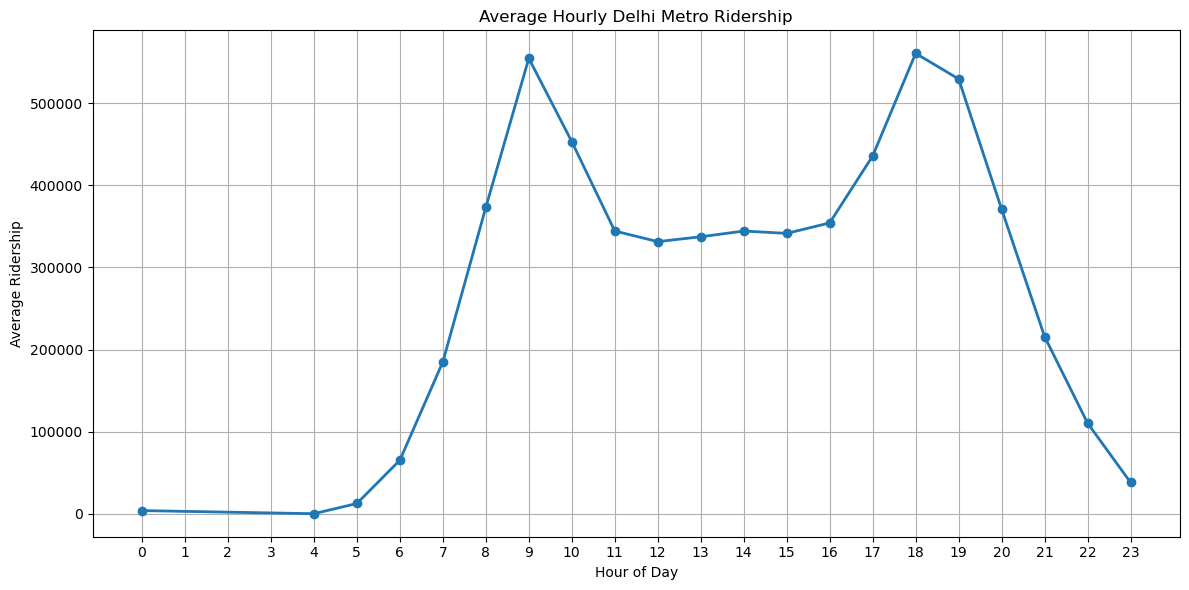

In [26]:
plt.plot(
    hourly_summary["hour"],
    hourly_summary["Average_Ridership"],
    marker="o",
    linewidth=2
)
plt.title("Average Hourly Delhi Metro Ridership")
plt.xlabel("Hour of Day")
plt.ylabel("Average Ridership")
plt.xticks(range(24))
plt.tight_layout()
plt.show()

### Observations

- Ridership remains negligible between 00:00 and 04:00, corresponding to the Delhi Metro's non-operational hours.
- Passenger activity begins increasing after 04:00 as metro services commence.
- Ridership rises sharply between 07:00 and 09:00, indicating the morning commuting period.
- The morning peak occurs at approximately 09:00.
- Ridership decreases after the morning peak and remains relatively stable between 11:00 and 16:00.
- A second increase in ridership begins around 17:00.
- The evening peak occurs at approximately 18:00 and is slightly higher than the morning peak.
- Ridership declines steadily after 19:00 and decreases rapidly after 20:00 until the end of operational hours.
### Key Insights

- Delhi Metro ridership exhibits a clear bimodal distribution, with distinct morning and evening commuting peaks.
- The evening peak is slightly higher than the morning peak, suggesting stronger passenger movement during evening return journeys.
- Ridership remains relatively stable between the two peak periods, indicating sustained daytime travel beyond office commuting.
- Passenger demand is highly concentrated during operational commuting hours, making these periods the primary focus for future ridership forecasting and weather impact analysis.

# How much does each hour contribute to daily ridership

In [27]:
total_daily_ridership = hourly_summary["Average_Ridership"].sum()
total_daily_ridership

np.float64(5960451.9779005535)

In [30]:
hourly_summary["Percentage_Contribution"] = (
    hourly_summary["Average_Ridership"] /
    total_daily_ridership
) * 100

hourly_summary.head(24)

,hour,Average_Ridership,Percentage_Contribution
0,0,3910.44,6.56e-02
1,4,133.95,2.25e-03
2,5,12573.94,2.11e-01
3,6,65233.78,1.09e+00
4,7,184917.65,3.10e+00
5,8,373098.98,6.26e+00
6,9,554460.17,9.30e+00
7,10,453055.07,7.60e+00
8,11,344259.35,5.78e+00
9,12,331346.92,5.56e+00


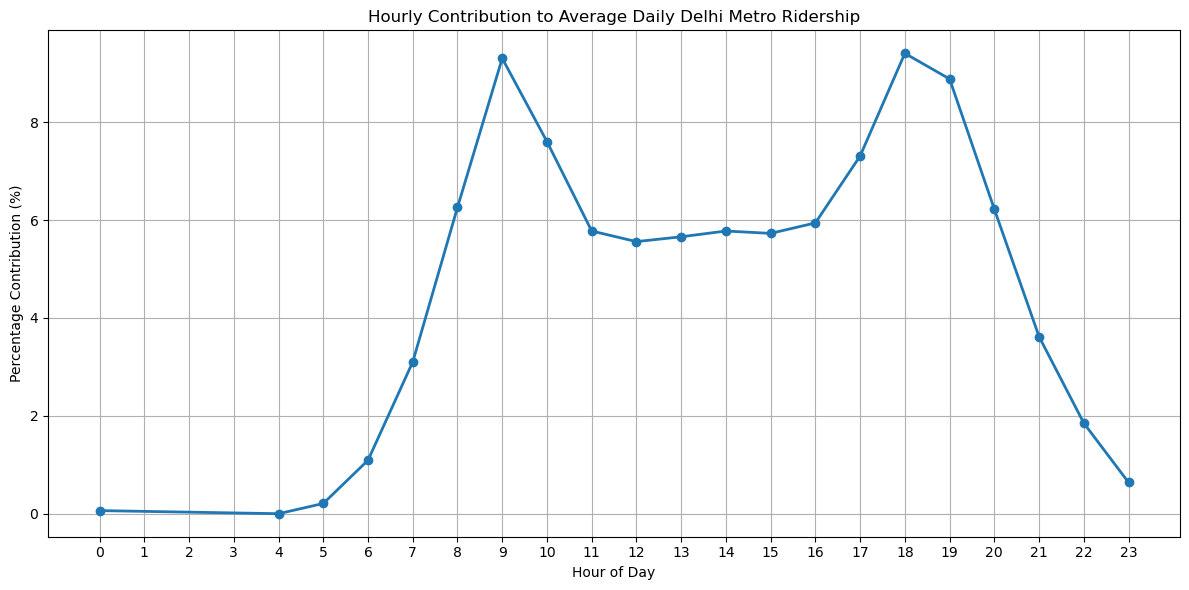

In [29]:
plt.plot(
    hourly_summary["hour"],
    hourly_summary["Percentage_Contribution"],
    marker="o",
    linewidth=2
)

plt.title("Hourly Contribution to Average Daily Delhi Metro Ridership")
plt.xlabel("Hour of Day")
plt.ylabel("Percentage Contribution (%)")
plt.xticks(range(24))

plt.tight_layout()
plt.show()

In [31]:
hourly_summary.sort_values(
    by="Percentage_Contribution",
    ascending=False
).head(5)

,hour,Average_Ridership,Percentage_Contribution
15,18,560512.56,9.40
6,9,554460.17,9.30
16,19,529328.45,8.88
7,10,453055.07,7.60
14,17,435585.89,7.31


### Observations

- Passenger contribution remains negligible between 00:00 and 04:00 due to non-operational hours.
- Hourly contribution increases rapidly after 07:00, leading to the morning peak at 09:00 (9.30%).
- The highest hourly contribution occurs at 18:00, accounting for 9.40% of the average daily ridership.
- The top five contributing hours are 18:00, 09:00, 19:00, 10:00, and 17:00.
- Between 11:00 and 16:00, each hour consistently contributes approximately 5.5–6.0% of the average daily ridership.
- Hourly contribution declines steadily after 19:00 until the end of service hours.

### Key Insights

- Daily ridership is concentrated within a few peak commuting hours.
- The evening peak contributes slightly more to daily ridership than the morning peak.
- Midday ridership remains stable, indicating sustained travel demand beyond peak commuting periods.
- Peak hours should be prioritised for ridership forecasting and weather impact analysis.

In [32]:
# Display the top 5 hours contributing to average daily ridership

top5_contribution = (
    hourly_summary
    .sort_values(
        by="Percentage_Contribution",
        ascending=False
    )
    .head(5)
)

top5_contribution = (
    top5_contribution[
        ["hour", "Average_Ridership", "Percentage_Contribution"]
    ]
    .round({
        "Average_Ridership": 0,
        "Percentage_Contribution": 2
    })
)

top5_contribution

,hour,Average_Ridership,Percentage_Contribution
15,18,560513.0,9.40
6,9,554460.0,9.30
16,19,529328.0,8.88
7,10,453055.0,7.60
14,17,435586.0,7.31


# how does metro ridership change fro one hour to the next hour?
### Objective
- Determine the hourly increase or decrease in ridership to identify the periods with the most rapid changes in passenger demand.

In [36]:
# Calculate the hour-to-hour change in average ridership
hourly_change = hourly_summary.copy()

hourly_change["Ridership_Change"] = (
    hourly_change["Average_Ridership"].diff()
)

# Create interval labels (e.g., 07:00–08:00)
hourly_change["Interval"] = (
    (hourly_change["hour"] - 1).astype(int).astype(str).str.zfill(2)
    + ":00–"
    + hourly_change["hour"].astype(int).astype(str).str.zfill(2)
    + ":00"
)

# Remove the first row since it has no previous hour
hourly_change = hourly_change.iloc[1:].reset_index(drop=True)

hourly_change.head()

,hour,Average_Ridership,Percentage_Contribution,Ridership_Change,Interval
0,4,133.95,2.25e-03,-3776.49,03:00–04:00
1,5,12573.94,2.11e-01,12439.99,04:00–05:00
2,6,65233.78,1.09e+00,52659.85,05:00–06:00
3,7,184917.65,3.10e+00,119683.87,06:00–07:00
4,8,373098.98,6.26e+00,188181.33,07:00–08:00


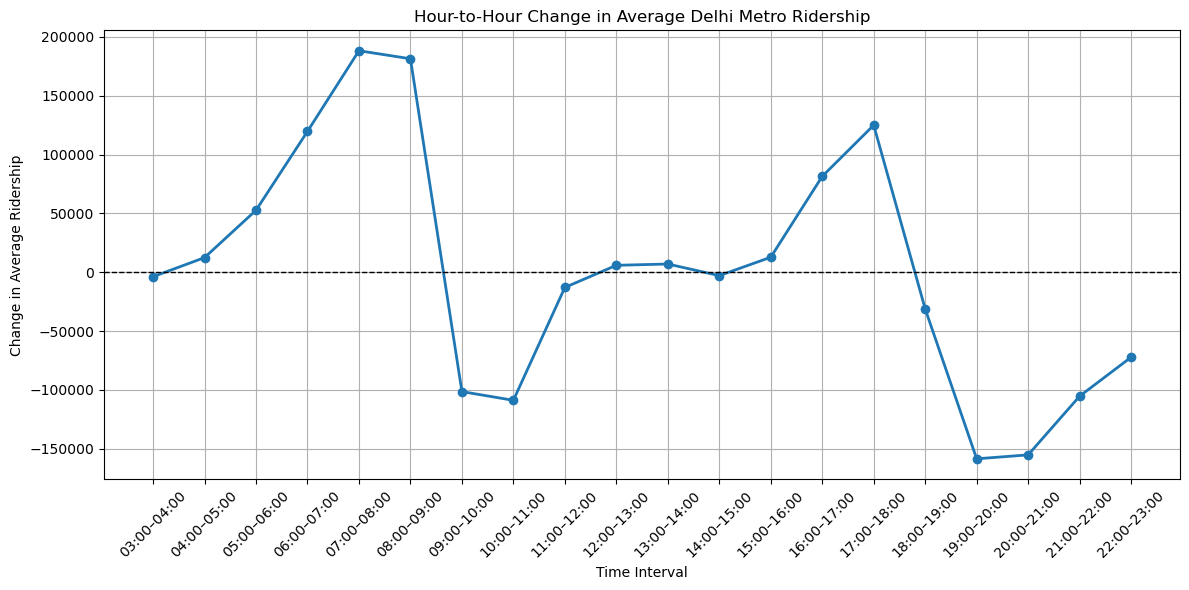

In [37]:
plt.plot(
    hourly_change["Interval"],
    hourly_change["Ridership_Change"],
    marker="o",
    linewidth=2
)

plt.axhline(
    y=0,
    color="black",
    linestyle="--",
    linewidth=1
)

plt.title("Hour-to-Hour Change in Average Delhi Metro Ridership")
plt.xlabel("Time Interval")
plt.ylabel("Change in Average Ridership")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [41]:
# Find the largest increase and decrease in ridership

largest_increase = (
    hourly_change
    .nlargest(1, "Ridership_Change")
    [["Interval", "Ridership_Change"]]
    .round({"Ridership_Change": 2})
)

largest_decrease = (
    hourly_change
    .nsmallest(1, "Ridership_Change")
    [["Interval", "Ridership_Change"]]
    .round({"Ridership_Change": 2})
)

print("Largest Increase")
display(largest_increase)

print("\nLargest Decrease")
display(largest_decrease)

Largest Increase


,Interval,Ridership_Change
4,07:00–08:00,188181.33



Largest Decrease


,Interval,Ridership_Change
16,19:00–20:00,-158500.44


### Observations

- Ridership increases continuously from 04:00–05:00 and reaches its fastest growth during **07:00–08:00**, with an increase of approximately **188,181** passengers.
- The largest decline occurs during **19:00–20:00**, with a decrease of approximately **158,500** passengers.
- A sharp decline is also observed immediately after the morning peak (09:00–11:00).
- Midday ridership changes remain relatively small, indicating stable passenger demand between peak periods.
- Ridership rises again between **16:00–18:00**, marking the onset of the evening peak.
### Key Insights

- Passenger demand changes most rapidly during the beginning and end of peak commuting periods.
- The morning rush develops more gradually, whereas the evening rush ends with a sharper decline.
- Stable hour-to-hour changes during midday indicate consistent off-peak travel demand.
- Hours exhibiting the largest changes are likely to be the most sensitive to external factors such as weather and should receive greater attention during forecasting.

# Calculate the average hourly Entry and Exit ridership


In [44]:
# Calculate the average hourly Entry and Exit ridership

hourly_entry_exit = (
    daily_hourly_total
    .groupby("hour")
    .agg(
        Average_Entry=("Entry", "mean"),
        Average_Exit=("Exit", "mean")
    )
    .reset_index()
)

hourly_entry_exit.head()

,hour,Average_Entry,Average_Exit
0,0,70.49,3839.95
1,4,109.55,24.40
2,5,11992.55,581.39
3,6,48618.29,16615.50
4,7,116682.67,68234.98


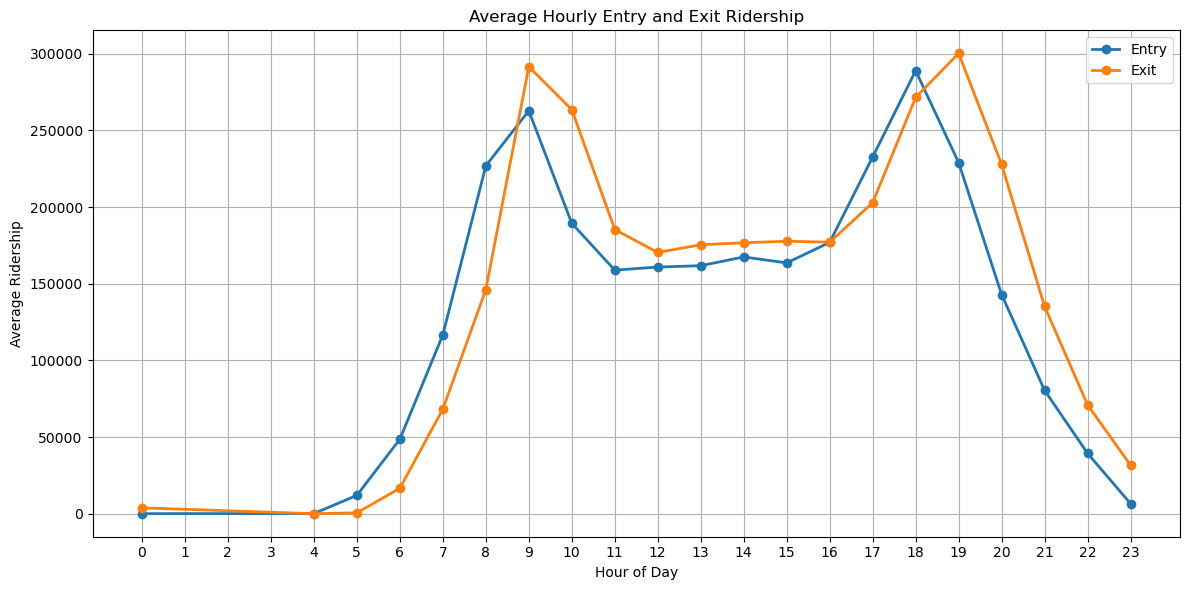

In [45]:
plt.plot(
    hourly_entry_exit["hour"],
    hourly_entry_exit["Average_Entry"],
    marker="o",
    linewidth=2,
    label="Entry"
)

plt.plot(
    hourly_entry_exit["hour"],
    hourly_entry_exit["Average_Exit"],
    marker="o",
    linewidth=2,
    label="Exit"
)

plt.title("Average Hourly Entry and Exit Ridership")
plt.xlabel("Hour of Day")
plt.ylabel("Average Ridership")

plt.xticks(range(24))

plt.legend()

plt.tight_layout()
plt.show()

In [46]:
peak_entry = (
    hourly_entry_exit
    .nlargest(1, "Average_Entry")
    [["hour", "Average_Entry"]]
    .round({"Average_Entry": 0})
)

peak_exit = (
    hourly_entry_exit
    .nlargest(1, "Average_Exit")
    [["hour", "Average_Exit"]]
    .round({"Average_Exit": 0})
)

print("Peak Entry Hour")
display(peak_entry)

print("\nPeak Exit Hour")
display(peak_exit)

Peak Entry Hour


,hour,Average_Entry
15,18,288989.0



Peak Exit Hour


,hour,Average_Exit
16,19,300291.0


### Observations

- Entry ridership peaks at **18:00** (288,989 passengers), while Exit ridership peaks at **19:00** (300,291 passengers).
- Entry ridership is higher than Exit ridership during the morning commute.
- Exit ridership dominates during the evening commute.
- Entry and Exit ridership are nearly equal around **16:00**.
- Both Entry and Exit follow a clear morning and evening peak pattern.

### Key Insights

- Morning travel is characterised by passenger entries, whereas evening travel is dominated by passenger exits.
- The one-hour lag between the Entry and Exit peaks reflects typical commuter movement across the metro network.
- The distinct temporal patterns indicate that Entry and Exit ridership should be modelled separately in subsequent forecasting analyses.